In [93]:
import operator
from langgraph.graph import StateGraph,START,END
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import PydanticOutputParser,StrOutputParser
from langchain_openai import ChatOpenAI
from pydantic import BaseModel,Field
from typing import TypedDict,Literal,Optional,Annotated
from dotenv import load_dotenv

In [94]:
load_dotenv()

True

In [95]:
llm=ChatOpenAI(model='gpt-4o')

In [96]:
str_parser=StrOutputParser()

In [97]:
class BlogSchema(BaseModel):
    blog:str=Field(description="detailed blog on given topic")
    

In [98]:
class BlogRatingSchema(BaseModel):
    rating:int = Field(description="rating of the blog",lt=11,gt=0)
    feedback:str=Field(description="feedback of the blog")

In [99]:
class BlogState(TypedDict):
    topic:str
    blog:str
    rating:int
    summary:str
    blog_attemts:int = 5
    feedback:str


In [100]:
rating_parser=PydanticOutputParser(pydantic_object=BlogRatingSchema)

In [101]:
def generate_blog(state:BlogState):
    print(state)
    blog_prompt = PromptTemplate(
        input_variables=["topic"],
        template="""You are an experienced content writer and professional blogger.
        Your task is to write a detailed, engaging, and informative blog
        on the following topic:

        Topic: {topic}

        Follow these instructions carefully:

        1. Create an attractive and relevant blog title.
        2. Write an engaging introduction explaining the topic.
        3. Organize the blog into clear sections using appropriate headings.
        4. Explain each section in detail using simple, understandable language.
        5. Include practical examples wherever relevant.
        6. Include the benefits, challenges, and real-world applications
        of the topic wherever applicable.
        7. Provide actionable tips or recommendations for readers.
        8. Maintain a professional yet conversational tone.
        9. Avoid unnecessary repetition and irrelevant information.
        10. Include a conclusion summarizing the key takeaways.
        11. Add 3 frequently asked questions (FAQs) with answers.
        12. Do not invent statistics, research findings, or citations.

        Expected output structure:

        # Blog Title

        ## Introduction

        ## Main Content
        (Use relevant headings and detailed explanations.)

        ## Practical Examples
        (Include examples relevant to the topic.)

        ## Key Takeaways

        ## Conclusion

        ## Frequently Asked Questions
        (Include 3 questions with answers.)

        Generate a comprehensive blog that is detailed, well-structured,
        and useful to the target audience.

        Return only the completed blog.
        """
        )

    chain= blog_prompt | llm | str_parser
    response= chain.invoke({'topic':state['topic']})
    return {'blog':response}

In [102]:
def evaluate_blog(state:BlogState):

    blog_review_prompt = PromptTemplate(
    input_variables=["blog"],
    partial_variables={
        "format_instructions": rating_parser.get_format_instructions()
    },
    template="""
    You are a professional blog reviewer and content quality evaluator.

    Your task is to carefully review the following blog and provide:
    1. An overall quality rating between 1 and 10.
    2. Constructive feedback explaining the blog's strengths and areas
    that need improvement.

    BLOG CONTENT:
    -------------------------
    {blog}
    -------------------------

    Evaluate the blog using the following 5 criteria.

    1. CONTENT QUALITY (0-2 points)
    - Relevance to the topic
    - Completeness and depth of explanation
    - Usefulness and accuracy of the information

    2. LANGUAGE QUALITY (0-2 points)
    - Grammar and spelling
    - Sentence construction
    - Vocabulary and readability

    3. TONE (0-2 points)
    - Appropriate tone for the intended audience
    - Professional and engaging writing style
    - Consistency of tone throughout the blog

    4. CLARITY OF THOUGHTS (0-2 points)
    - Logical flow of ideas
    - Clear explanations
    - Coherent paragraphs and transitions

    5. STRUCTURE AND READABILITY (0-2 points)
    - Effective headings and subheadings
    - Well-organized paragraphs
    - Appropriate introduction and conclusion

    SCORING INSTRUCTIONS:
    - Award 0, 1, or 2 points for each criterion.
    - Add the points from all 5 criteria.
    - The total score must be an integer between 0 and 10.
    - If the total score is 0, return a rating of 1.
    - Be objective and evaluate the actual quality of the blog.
    - Do not give a high score merely because the blog is long.
    - Do not penalize a concise blog if it covers the topic effectively.
    - Do not invent problems that are not present in the blog.
    - Do not claim to have externally verified factual accuracy.

    FEEDBACK INSTRUCTIONS:
    - Explain the blog's main strengths.
    - Identify specific weaknesses that reduce its quality.
    - Suggest practical improvements where appropriate.
    - Make the feedback constructive, clear, and concise.
    - Ensure the feedback is consistent with the assigned rating.

    OUTPUT RULES:
    - Return both the rating and feedback according to the required schema.
    - Do not return any additional text outside the structured output.

    {format_instructions}
    """
    )

    chain = blog_review_prompt | llm | rating_parser
    response= chain.invoke({'blog':state['blog']})
    blog_attempts=state['blog_attemts']+1
    return {'rating':response.rating,'blog_attemts':blog_attempts,'feedback':response.feedback}

In [103]:
def generate_blog_summary(state:BlogState):

    blog_summary_prompt = PromptTemplate(
        input_variables=["blog"],
        template="""
    You are a professional content summarizer.

    Your task is to summarize the following detailed blog into
    2-3 concise bullet points.

    BLOG CONTENT:
    -------------------------
    {blog}
    -------------------------

    Instructions:
    1. Identify the main topic and the most important takeaways.
    2. Write only 2-3 bullet points.
    3. Keep each bullet point to one concise line.
    4. Preserve the original meaning and key information.
    5. Use simple, clear, and easy-to-understand language.
    6. Avoid unnecessary details, repetition, and introductory statements.
    7. Do not add information that is not present in the blog.

    Output format:

    - First key takeaway.
    - Second key takeaway.
    - Third key takeaway (only if necessary).

    Return only the bullet-point summary. Do not include a title,
    introduction, or conclusion.
    """
    )

    chain = blog_summary_prompt | llm | str_parser

    response= chain.invoke({'blog':state['blog']})
    return {'summary':response}


In [104]:
from langchain_core.prompts import ChatPromptTemplate


def optimize_blog(state:BlogState):

    optimize_blog_prompt = ChatPromptTemplate.from_messages([
        (
            "system",
            """
            You are a professional blog editor and content optimizer.

            Your task is to improve an existing blog based on its quality
            rating and the feedback provided by a blog evaluator.

            Instructions:

            1. Carefully read the original blog, its rating, and the
            evaluator's feedback.

            2. Use the rating to understand the overall quality of the
            original blog.

            3. Address the specific weaknesses identified in the feedback.
            Improve content quality, language, grammar, tone, clarity
            of thoughts, logical flow, structure, and readability
            wherever necessary.

            4. Preserve the original topic, intended meaning, important
            information, and useful examples.

            5. Rewrite and improve the complete blog, not just individual
            sentences or paragraphs.

            6. Avoid unnecessary repetition and irrelevant information.

            7. Do not invent facts, statistics, research findings, or
            citations.

            8. If the original blog already contains strong sections,
            preserve them and focus on the identified weaknesses.

            9. The objective is to produce a higher-quality blog that
            addresses the evaluator's feedback.

            IMPORTANT:
            - Do not evaluate or rate the blog again.
            - Do not return the feedback or rating.
            - Do not explain what changes you made.
            - Return only the complete, optimized blog.
            """
        ),
        (
            "human",
            """
            Optimize the following blog using the evaluator's rating
            and feedback.

            ORIGINAL BLOG:
            -------------------------
            {blog}
            -------------------------

            EVALUATOR RATING: {rating}/10

            EVALUATOR FEEDBACK:
            -------------------------
            {feedback}
            -------------------------

            Produce the complete improved version of the original blog.
            """
        )
    ])

    chain = optimize_blog_prompt | llm | str_parser
    response = chain.invoke({'blog':state['blog'],'rating':state['rating'],'feedback':state['feedback']})
    return {'blog':response}

In [ ]:
def check_blog_evaluation(state:BlogState)-> Literal['optimize_blog','generate_blog_summary']:
    rating = state['rating']
    
    blog_attemts=state['blog_attemts']

    feedback = state['feedback']

    print(f"RATING : {rating} ; BLOG ATTEMPTS : {blog_attemts} ; FEEDBACK : {feedback}")
    if rating >=9 and blog_attemts<=5:
        # print("Condition Satisfy")
        return 'generate_blog_summary'
    # elif blog_attemts>5:
    #     return END
    else :
        # print("Goes To Optimize Blog \n")
        

        return 'optimize_blog'

In [131]:
graph = StateGraph(BlogState)

In [132]:
# Add Nodes

graph.add_node('generate_blog',generate_blog)
graph.add_node('evaluate_blog',evaluate_blog)
graph.add_node('optimize_blog',optimize_blog)
graph.add_node('generate_blog_summary',generate_blog_summary)

graph.add_edge(START,'generate_blog')
graph.add_edge('generate_blog','evaluate_blog')
graph.add_conditional_edges('evaluate_blog',check_blog_evaluation)
graph.add_edge('optimize_blog','evaluate_blog')
graph.add_edge('generate_blog_summary',END)

In [133]:
workflow=graph.compile()

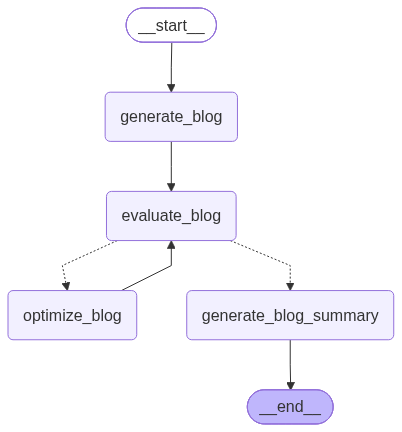

In [134]:
workflow

In [135]:
initial_state= {'topic':'Indian Roads','blog_attemts':0}

In [140]:
final_state=workflow.invoke(initial_state)

{'topic': 'Indian Roads', 'blog_attemts': 0}
RATING : 8 ; BLOG ATTEMPTS : 1 ; FEEDBACK : The blog effectively explores the intricacies and significance of Indian roads, providing a comprehensive overview that is both informative and engaging. 

Strengths:
1. Content Quality: The blog is detailed and well-researched, covering various aspects of the Indian road network and providing useful examples such as the Golden Quadrilateral.
2. Language Quality: The language is clear and professional, with correct grammar and spelling. The vocabulary is suitable for an educated audience, enhancing readability.
3. Tone: The blog maintains an engaging and informative tone throughout, which is appropriate for readers interested in understanding the challenges and developments of Indian roads.
4. Structure and Readability: The use of clear headings and subheadings helps organize the content effectively, providing a logical flow of information.

Areas for Improvement:
1. Clarity of Thoughts: While most

In [141]:
final_state

{'topic': 'Indian Roads',
 'blog': "# Navigating the Indian Roads: A Journey Through Chaos and Charm\n\n## Introduction\n\nIndian roads are a captivating blend of history, culture, and modernity. Stretching from the bustling metropolitan cities to the tranquil rural landscapes, India's road network weaves through the nation, offering a diverse tapestry of experiences. This journey, while challenging, is uniquely rewarding for travelers and commuters alike. Join us as we explore the significance, complexities, and everyday realities of Indian roads, unraveling their crucial role in the lives of millions.\n\n## Main Content\n\n### The Significance of Indian Roads\n\nIndia boasts one of the largest road networks globally, extending over 5.89 million kilometers. These roads serve as the nation's lifelines, linking remote villages to urban centers and facilitating the movement of over 70% of the country's freight and nearly 85% of passenger traffic. Indian roads not only boost economic deve